<a href="https://colab.research.google.com/github/Mohanapriyaa31/flight-delay-airline-analysis/blob/main/flight_delay_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving airlines.csv to airlines (2).csv
Saving flights.csv.zip to flights.csv.zip
Saving airports.csv to airports.csv


In [ ]:
import os
os.listdir()

['.config',
 'airlines.csv',
 'airlines (1).csv',
 'airlines (2).csv',
 'airports.csv',
 'flights.csv.zip',
 'sample_data']

In [ ]:
import pandas as pd

df = pd.read_csv("flights.csv.zip", nrows=10000)

df.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Information about the dataset
print("\nDataset information:")
df.info()

Dataset shape: (10000, 31)

Column names:
['YEAR', 'MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'FLIGHT_NUMBER', 'TAIL_NUMBER', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_DEPARTURE', 'DEPARTURE_TIME', 'DEPARTURE_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'SCHEDULED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'WHEELS_ON', 'TAXI_IN', 'SCHEDULED_ARRIVAL', 'ARRIVAL_TIME', 'ARRIVAL_DELAY', 'DIVERTED', 'CANCELLED', 'CANCELLATION_REASON', 'AIR_SYSTEM_DELAY', 'SECURITY_DELAY', 'AIRLINE_DELAY', 'LATE_AIRCRAFT_DELAY', 'WEATHER_DELAY']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 10000 non-null  int64  
 1   MONTH                10000 non-null  int64  
 2   DAY                  10000 non-null  int64  
 3   DAY_OF_WEEK          10000 non-null  int64  
 4   AIRLINE              10000 non-nul

In [ ]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (10000, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 10000 non-null  int64  
 1   MONTH                10000 non-null  int64  
 2   DAY                  10000 non-null  int64  
 3   DAY_OF_WEEK          10000 non-null  int64  
 4   AIRLINE              10000 non-null  object 
 5   FLIGHT_NUMBER        10000 non-null  int64  
 6   TAIL_NUMBER          9987 non-null   object 
 7   ORIGIN_AIRPORT       10000 non-null  object 
 8   DESTINATION_AIRPORT  10000 non-null  object 
 9   SCHEDULED_DEPARTURE  10000 non-null  int64  
 10  DEPARTURE_TIME       9612 non-null   float64
 11  DEPARTURE_DELAY      9612 non-null   float64
 12  TAXI_OUT             9611 non-null   float64
 13  WHEELS_OFF           9611 non-null   float64
 14  SCHEDULED_TIME       10000 non-null  int64  
 15  ELAPSED_TI

In [ ]:
print(df.isnull().sum())

YEAR                      0
MONTH                     0
DAY                       0
DAY_OF_WEEK               0
AIRLINE                   0
FLIGHT_NUMBER             0
TAIL_NUMBER              13
ORIGIN_AIRPORT            0
DESTINATION_AIRPORT       0
SCHEDULED_DEPARTURE       0
DEPARTURE_TIME          388
DEPARTURE_DELAY         388
TAXI_OUT                389
WHEELS_OFF              389
SCHEDULED_TIME            0
ELAPSED_TIME            407
AIR_TIME                407
DISTANCE                  0
WHEELS_ON               395
TAXI_IN                 395
SCHEDULED_ARRIVAL         0
ARRIVAL_TIME            395
ARRIVAL_DELAY           407
DIVERTED                  0
CANCELLED                 0
CANCELLATION_REASON    9608
AIR_SYSTEM_DELAY       8272
SECURITY_DELAY         8272
AIRLINE_DELAY          8272
LATE_AIRCRAFT_DELAY    8272
WEATHER_DELAY          8272
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (10000, 31)


In [ ]:
empty_columns = df.columns[df.isnull().all()].tolist()
print("Completely empty columns:", empty_columns)

df = df.dropna(axis=1, how="all")

Completely empty columns: []


In [ ]:
for col in df.columns:
    if df[col].isnull().any():
        if df[col].dtype in ["int64", "float64"]:
            df[col] = df[col].fillna(df[col].median())
        else:
            mode_values = df[col].mode()
            if not mode_values.empty:
                df[col] = df[col].fillna(mode_values[0])

print("Missing values remaining:", df.isnull().sum().sum())

Missing values remaining: 0


In [ ]:
print(df.dtypes)

YEAR                     int64
MONTH                    int64
DAY                      int64
DAY_OF_WEEK              int64
AIRLINE                 object
FLIGHT_NUMBER            int64
TAIL_NUMBER             object
ORIGIN_AIRPORT          object
DESTINATION_AIRPORT     object
SCHEDULED_DEPARTURE      int64
DEPARTURE_TIME         float64
DEPARTURE_DELAY        float64
TAXI_OUT               float64
WHEELS_OFF             float64
SCHEDULED_TIME           int64
ELAPSED_TIME           float64
AIR_TIME               float64
DISTANCE                 int64
WHEELS_ON              float64
TAXI_IN                float64
SCHEDULED_ARRIVAL        int64
ARRIVAL_TIME           float64
ARRIVAL_DELAY          float64
DIVERTED                 int64
CANCELLED                int64
CANCELLATION_REASON     object
AIR_SYSTEM_DELAY       float64
SECURITY_DELAY         float64
AIRLINE_DELAY          float64
LATE_AIRCRAFT_DELAY    float64
WEATHER_DELAY          float64
dtype: object


In [ ]:
print("Final shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

display(df.head())

Final shape: (10000, 31)
Total missing values: 0
Total duplicate rows: 0


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,B,3.0,0.0,8.0,0.0,0.0
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,B,3.0,0.0,8.0,0.0,0.0
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,B,3.0,0.0,8.0,0.0,0.0
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,B,3.0,0.0,8.0,0.0,0.0
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,B,3.0,0.0,8.0,0.0,0.0


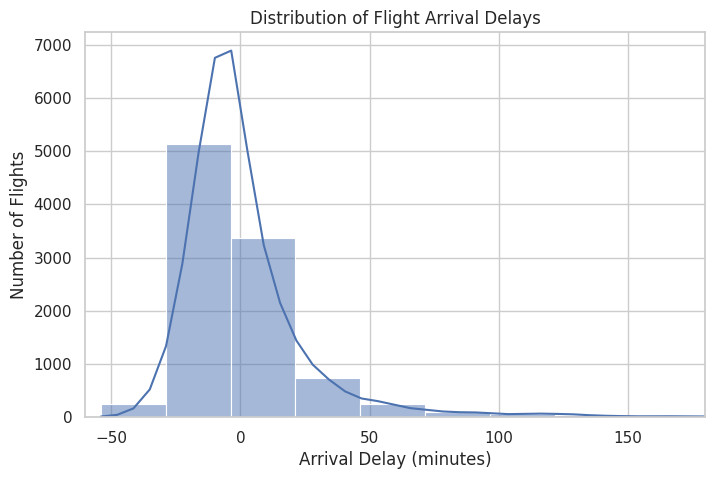

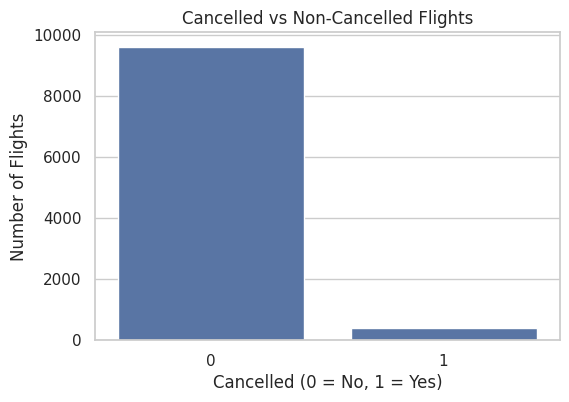

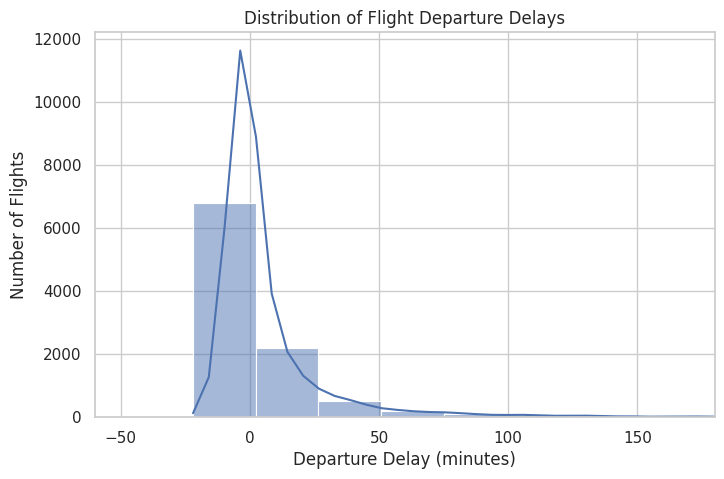

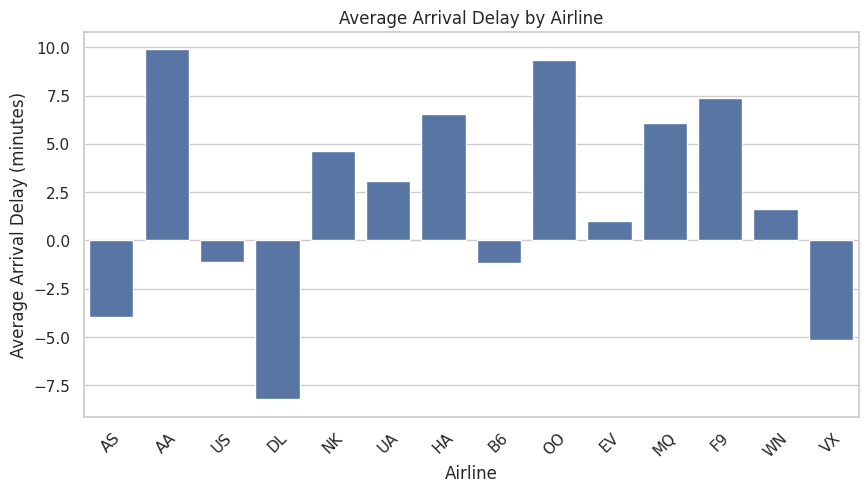

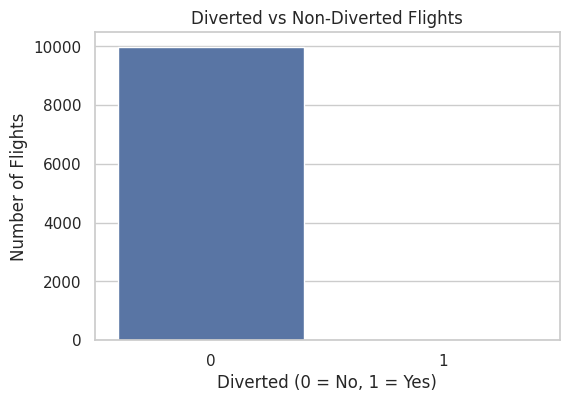

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Distribution of arrival delays
plt.figure(figsize=(8, 5))
sns.histplot(df["ARRIVAL_DELAY"], bins=50, kde=True)
plt.title("Distribution of Flight Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.xlim(-60, 180)
plt.show()

# 2. Cancelled vs non-cancelled flights
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="CANCELLED")
plt.title("Cancelled vs Non-Cancelled Flights")
plt.xlabel("Cancelled (0 = No, 1 = Yes)")
plt.ylabel("Number of Flights")
plt.show()

# 3. Distribution of departure delays
plt.figure(figsize=(8, 5))
sns.histplot(df["DEPARTURE_DELAY"], bins=50, kde=True)
plt.title("Distribution of Flight Departure Delays")
plt.xlabel("Departure Delay (minutes)")
plt.ylabel("Number of Flights")
plt.xlim(-60, 180)
plt.show()

# 4. Average arrival delay by airline
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x="AIRLINE", y="ARRIVAL_DELAY",
            errorbar=None)
plt.title("Average Arrival Delay by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Arrival Delay (minutes)")
plt.xticks(rotation=45)
plt.show()

# 5. Flight diversion counts
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="DIVERTED")
plt.title("Diverted vs Non-Diverted Flights")
plt.xlabel("Diverted (0 = No, 1 = Yes)")
plt.ylabel("Number of Flights")
plt.show()


In [ ]:
df.to_csv("cleaned_flight_data.csv", index=False)

from google.colab import files
files.download("cleaned_flight_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

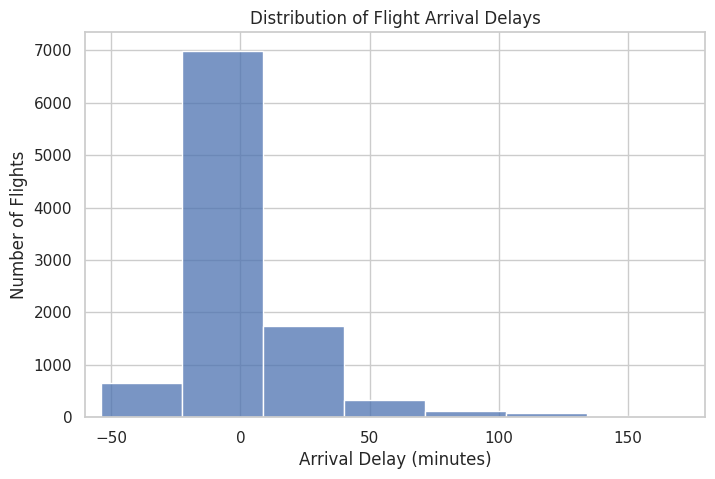

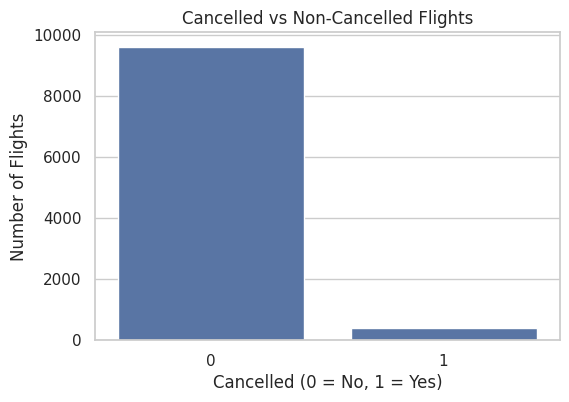

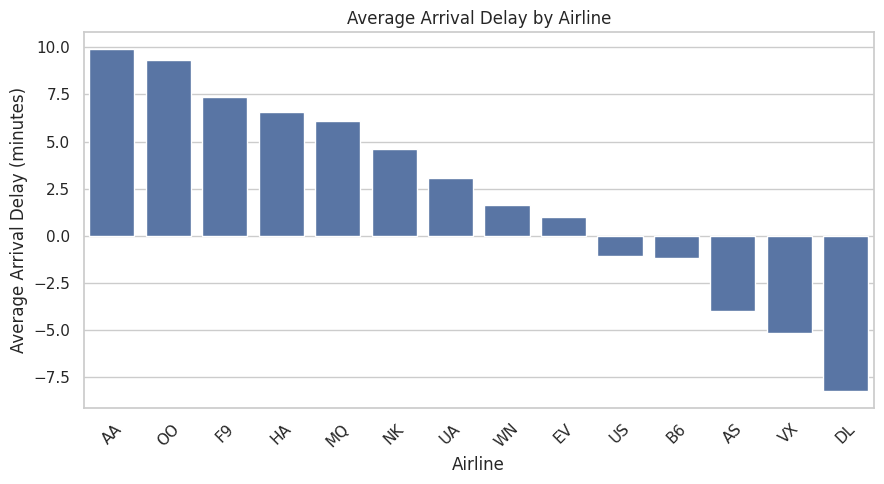

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Visualization 1: Arrival Delay Distribution
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="ARRIVAL_DELAY", bins=40)
plt.title("Distribution of Flight Arrival Delays")
plt.xlabel("Arrival Delay (minutes)")
plt.ylabel("Number of Flights")
plt.xlim(-60, 180)
plt.show()

# Visualization 2: Cancelled Flights
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="CANCELLED")
plt.title("Cancelled vs Non-Cancelled Flights")
plt.xlabel("Cancelled (0 = No, 1 = Yes)")
plt.ylabel("Number of Flights")
plt.show()

# Visualization 3: Average Arrival Delay by Airline
airline_delay = (
    df.groupby("AIRLINE")["ARRIVAL_DELAY"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(9, 5))
sns.barplot(data=airline_delay, x="AIRLINE", y="ARRIVAL_DELAY")
plt.title("Average Arrival Delay by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Arrival Delay (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
df.to_csv("cleaned_flight_data.csv", index=False)

from google.colab import files
files.download("cleaned_flight_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>